<a href="https://colab.research.google.com/github/AKookani/BrickwallCliffordCircuit/blob/main/Measurement%20induced%20dynamics%20with%20Stabilizer%20formalism.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit ipywidgets
!pip install pylatexenc
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.6 MB/s eta 0:00:00


StabilizerState(['+ZX', '-XZ'])


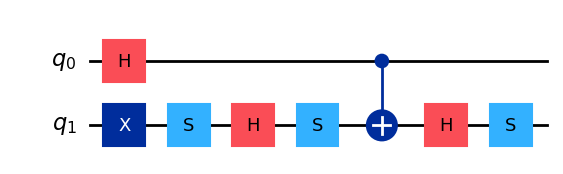

StabilizerState(['+ZX', '+YZ'])
StabilizerState(['+ZX', '-ZI'])
t=1: measured qubit 1 -> 1


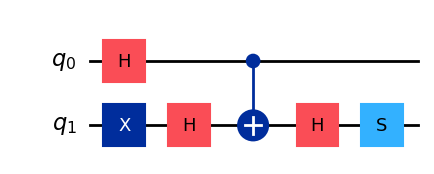

StabilizerState(['+YX', '-YI'])


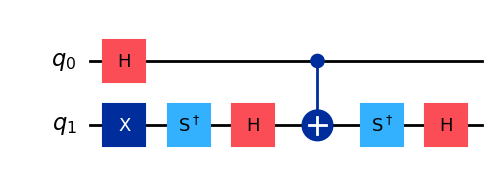

StabilizerState(['-XX', '+XI'])


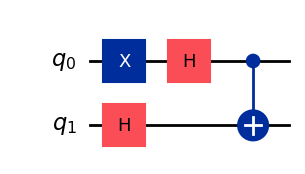

StabilizerState(['+ZX', '-ZI'])
StabilizerState(['+ZX', '-ZI'])
t=4: measured qubit 1 -> 1


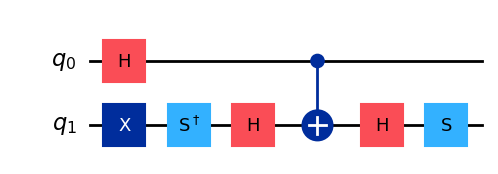

StabilizerState(['+YX', '-YI'])
StabilizerState(['-ZI', '-IX'])
t=5: measured qubit 1 -> 1


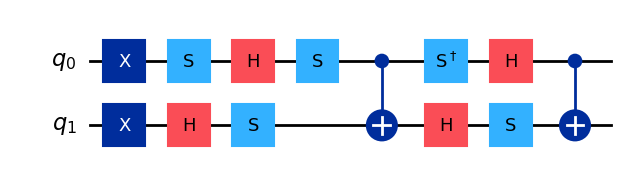

StabilizerState(['-ZI', '-IX'])
StabilizerState(['-ZI', '-IX'])
t=6: measured qubit 1 -> 1


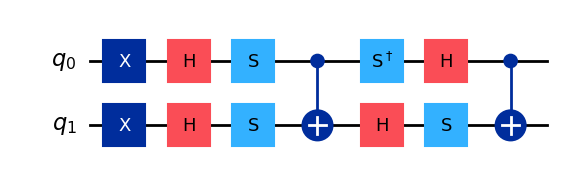

StabilizerState(['-XI', '-IX'])


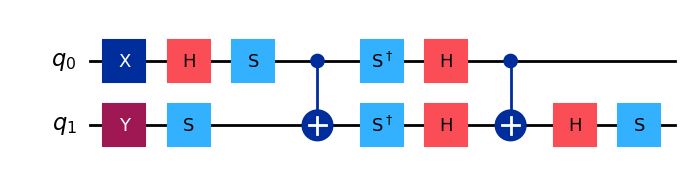

StabilizerState(['-YI', '-IX'])
StabilizerState(['+ZI', '-IX'])
t=8: measured qubit 1 -> 0


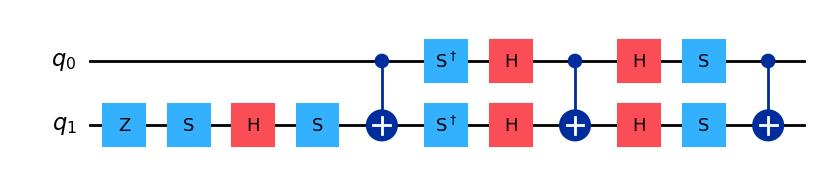

StabilizerState(['-ZI', '-IX'])
StabilizerState(['-ZI', '-IX'])
t=9: measured qubit 1 -> 1


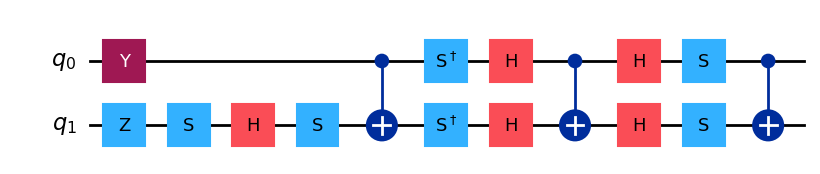

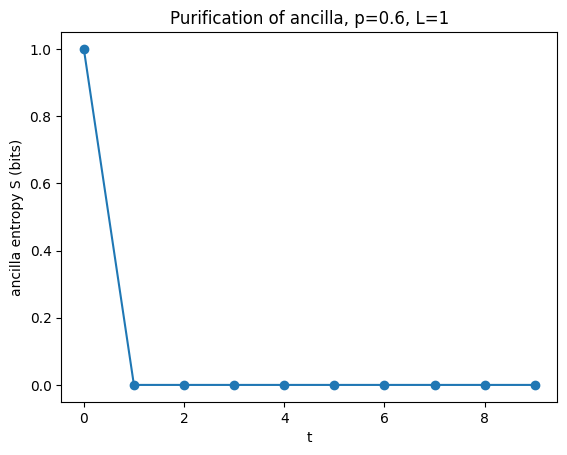

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import (StabilizerState, Clifford, Statevector,
                                 random_clifford, partial_trace, entropy)

size, T, p_measure = 1, 10, 0.6
rng = np.random.default_rng()

# Qubit 0 = ancilla, qubits 1..size = system
init = QuantumCircuit(size + 1)
init.h(0)
init.cx(0, 1 + size // 2)          # Bell pair: ancilla <-> middle system qubit
state = StabilizerState(init)

system = list(range(1, size + 1))
S_history = []

for t in range(T):
    # 1. Unitary layer: random Clifford on the system
    state = state.evolve(random_clifford(size, seed=rng), qargs=system)
    print(state)

    # 2. Measurement + reset on a random system qubit, with probability p
    if rng.random() < p_measure:
        q = int(rng.choice(system))
        outcome, state = state.measure([q])
        print(state)
        print(f"t={t}: measured qubit {q} -> {outcome}")

    # 3. Entanglement entropy of the ancilla (bits)
    q_cirq = state.clifford.to_circuit()
    psi = Statevector(q_cirq)
    display(q_cirq.draw('mpl', fold=-1))
    S_history.append(entropy(partial_trace(psi, system), base=2))

plt.plot(S_history, 'o-')
plt.xlabel('t'); plt.ylabel('ancilla entropy S (bits)')
plt.title(f'Purification of ancilla, p={p_measure}, L={size}')
plt.show()